<a href="https://colab.research.google.com/github/collenrosetamano-svg/IS110_repo_Tamano/blob/main/Copy_of_ML_Workbook_Wisconsin_Diagnostic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Workbook Exercise: Breast Cancer Diagnosis — An End-to-End Classification Project

**Course:** Machine Learning / Applied AI  **Level:** Intermediate  **Estimated time:** 2 hours

**Learning objectives.** By the end of this workbook you will be able to:
1. Frame a real-world problem as a supervised learning task.
2. Summarize and visualize a dataset to understand its structure before modeling.
3. Clean data, select informative features and apply appropriate transforms.
4. Build a leak-free test harness and spot-check several algorithms.
5. Improve accuracy through tuning and ensembles, then report honest test results.

**How to use this workbook.** Run the cells in order. Wherever you see `# TODO`, replace the `...` with your own code (hints are given). Cells marked ✏️ ask for a written answer: double-click to edit. Do not look at the answer key until you have tried each exercise.

**Outline**
- A. Problem Definition
- B. Summarize and Analyze Data
- C. Prepare Data
- D. Evaluate Algorithm
- E. Improve Accuracy



## Before you begin

> First, make a copy of this notebook so that you can make changes as you please.
> Run and edit the copy instead of this original notebook.

> To copy this notebook, go to `File|Save a Copy to Drive`.

**Gentle Reminder**
> Once finish, Kindly `push` this notebook to your GitHub repo.**

---
## A. Problem Definition

### A.1 Brief Description
The **Breast Cancer Wisconsin (Diagnostic)** dataset contains measurements computed from digitized images of fine-needle aspirates (FNA) of breast masses. Each row describes the characteristics of the cell nuclei present in one image.

- **569 instances**, **30 numeric features**, **1 binary target**
- Features are 10 nucleus measurements (radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, fractal dimension), each reported as the **mean**, the **standard error** and the **worst** (largest) value.
- Target: `0` = malignant, `1` = benign.

### A.2 Problem Statement
✏️ **Exercise A.1.** In 3–4 sentences, write a problem statement in your own words. Include: (a) the prediction task, (b) the input data, (c) the type of learning problem, (d) which kind of error is more costly and why, and (e) how you will judge success.

> Your answer:
(a) Prediction Task: The goal is to predict whether a breast tissue sample is malignant cancerous or benign non-cancerous.
(b) Input Data: The model uses continuous tabular features calculated from digitized images of fine needle aspirate FNA diagnostic scans of breast masses (e.g., cell radius, texture, perimeter, and area).
(c) Type of Learning Problem: This is a supervised binary classification problem because we are using pre-labeled dataset features to predict one of two target outcomes.
(d) Most Costly Error: A false negative diagnosing a malignant tumor as benign is significantly more costly. Missing a positive cancer case delays critical, life-saving medical interventions, allowing the disease to progress with severe patient health risks.
(e) Judging Success: I will judge model success primarily using recall sensitivity to minimize missed malignant cases, while monitoring $F_1$-score and ROC-AUC to ensure the model maintains strong precision and overall balance without over-predicting false positives.

### A.3 Load Packages
**Exercise A.2.** The imports below are mostly done. Add the classifier imports you will need in Parts C–E.

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    AdaBoostClassifier,
    VotingClassifier
)

# TODO: import LogisticRegression, LinearDiscriminantAnalysis, KNeighborsClassifier, DecisionTreeClassifier, GaussianNB, SVC, RandomForest, ExtraTrees, GradientBoosting, AdaBoost and VotingClassifier
...

try:
    display
except NameError:
    display = print

### A.4 Load Dataset
**Exercise A.3.** Load the data into a DataFrame named `df` (hint: `load_breast_cancer(as_frame=True)`).



> `url = [https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic]`

In [ ]:
from sklearn.datasets import load_breast_cancer

url = "https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic"

data = load_breast_cancer(as_frame=True)
df = data.frame

---
## B. Summarize and Analyze Data

### B.1 Descriptive Statistics
**Exercise B.1.** Inspect the dataset's dimensions, data types and the first rows.

In [ ]:
# TODO: print the shape, the counts of each dtype, and show the first 5 rows
...
print("Dataset Shape:", df.shape)
print("\nData Type Counts:")
print(df.dtypes.value_counts())
print("\nFirst 5 Rows:")
display(df.head())

Dataset Shape: (569, 31)

Data Type Counts:
float64    30
int64       1
Name: count, dtype: int64

First 5 Rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


**Exercise B.2.** Check for class imbalance. Print the count and the proportion of each class.

In [ ]:
# TODO: class counts and percentages
...
class_counts = df["target"].value_counts()
class_percentages = df["target"].value_counts(normalize=True) * 100

print("Class Counts:\n", class_counts)
print("\nClass Percentages (%):\n", class_percentages.round(2))

Class Counts:
 target
1    357
0    212
Name: count, dtype: int64

Class Percentages (%):
 target
1    62.74
0    37.26
Name: proportion, dtype: float64


**Exercise B.3.** Produce summary statistics (transposed so features are rows) and list the 10 most skewed features.

In [ ]:
# TODO: describe().T, then the 10 largest skewness values
...
summary_stats = df.describe().T
display(summary_stats)
skewed_features = df.skew().abs().nlargest(10)
print("10 Most Skewed Features (Absolute Skewness):\n", skewed_features)

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


10 Most Skewed Features (Absolute Skewness):
 area error                 5.447186
concavity error            5.110463
fractal dimension error    3.923969
perimeter error            3.443615
radius error               3.088612
smoothness error           2.314450
symmetry error             2.195133
compactness error          1.902221
worst area                 1.859373
worst fractal dimension    1.662579
dtype: float64


**Exercise B.4.** Compute the correlation of every feature with the target and show the 5 most negative and 5 most positive.

In [ ]:
# TODO: correlation with target, sorted
...
correlations = df.corr()["target"].drop("target").sort_values()

print("5 Most Negative Correlations:\n", correlations.head(5))
print("\n5 Most Positive Correlations:\n", correlations.tail(5))

5 Most Negative Correlations:
 worst concave points   -0.793566
worst perimeter        -0.782914
mean concave points    -0.776614
worst radius           -0.776454
mean perimeter         -0.742636
Name: target, dtype: float64

5 Most Positive Correlations:
 fractal dimension error   -0.077972
symmetry error             0.006522
texture error              0.008303
mean fractal dimension     0.012838
smoothness error           0.067016
Name: target, dtype: float64


✏️ **Question B.5.** What do the class proportions and the skewness tell you about the choice of evaluation metric and the need for transforms?

> Your answer: The dataset exhibits a moderate class imbalance (~63% benign vs. ~37% malignant), which means relying purely on standard accuracy can be misleading, making metrics like recall, precision, and $F_1$-score far better choices for evaluation. Additionally, high positive skewness in several features indicates skewed feature distributions and potential outliers, highlighting the need for data transformations (such as PowerTransformer, QuantileTransformer, or StandardScaler) to stabilize variance and improve model training performance for distance-based and linear algorithms.

### B.2 Data Visualization

**Exercise B.6 (univariate).** Plot histograms of the ten `mean` features.

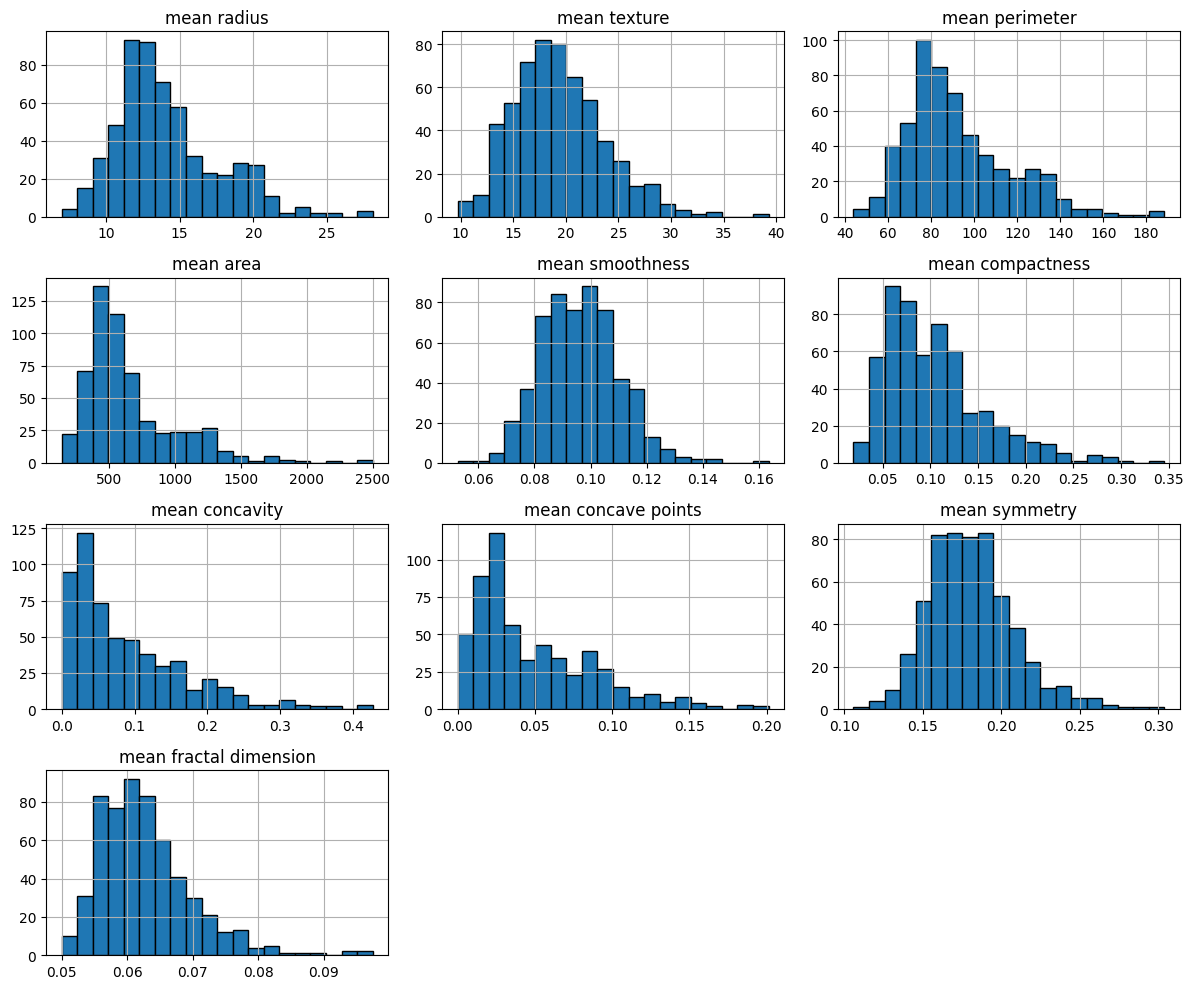

In [ ]:
# TODO: histograms of the ten "mean" features (hint: df.filter(like="mean").hist)
...
df.filter(like="mean").hist(figsize=(12, 10), bins=20, edgecolor="black")
plt.tight_layout()
plt.show()

**Exercise B.7 (bivariate).** Draw box plots of four features split by class. Which separate the classes best?

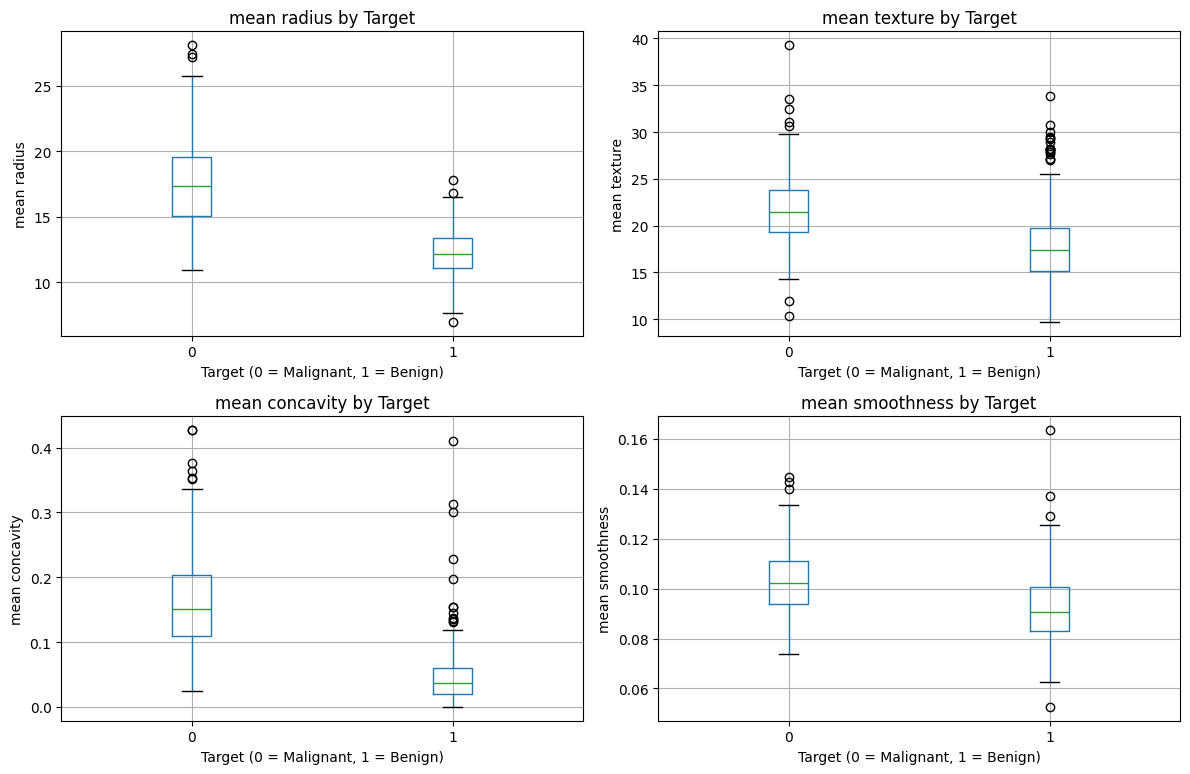

In [ ]:
features = ["mean radius", "mean texture", "mean concavity", "mean smoothness"]
# TODO: one box plot per feature, grouped by target
...
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, feature in zip(axes.flatten(), features):
    df.boxplot(column=feature, by="target", ax=ax)
    ax.set_title(f"{feature} by Target")
    ax.set_xlabel("Target (0 = Malignant, 1 = Benign)")
    ax.set_ylabel(feature)

plt.suptitle("")  # Remove default pandas title
plt.tight_layout()
plt.show()

**Exercise B.8 (multivariate).** Show a correlation heatmap of the ten `mean` features.

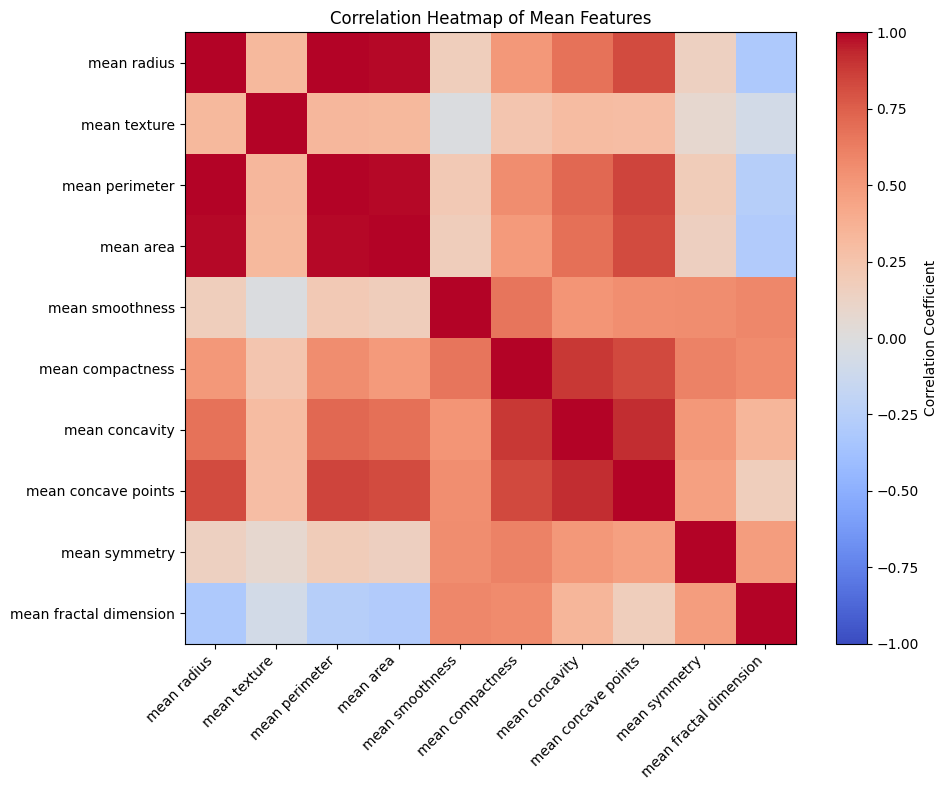

In [ ]:
# TODO: correlation matrix of the "mean" features drawn with imshow
...
mean_df = df.filter(like="mean")
corr = mean_df.corr()

plt.figure(figsize=(10, 8))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation Coefficient")

plt.xticks(
    range(len(mean_df.columns)),
    mean_df.columns,
    rotation=45,
    ha="right",
)
plt.yticks(range(len(mean_df.columns)), mean_df.columns)
plt.title("Correlation Heatmap of Mean Features")
plt.tight_layout()
plt.show()

**Exercise B.9.** Scatter `mean radius` against `mean concavity`, coloured by class.

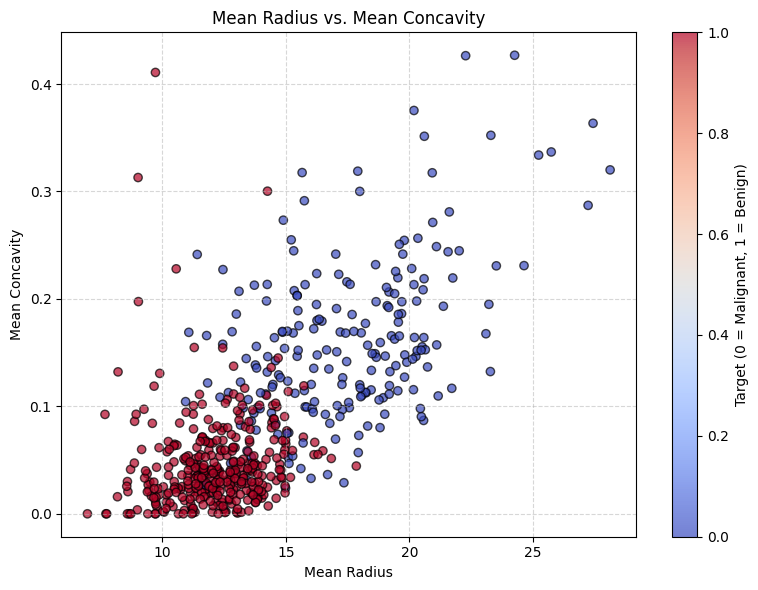

In [ ]:
# TODO: coloured scatter plot with axis labels and a colourbar
...
plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    df["mean radius"],
    df["mean concavity"],
    c=df["target"],
    cmap="coolwarm",
    alpha=0.7,
    edgecolors="k",
)

plt.xlabel("Mean Radius")
plt.ylabel("Mean Concavity")
plt.title("Mean Radius vs. Mean Concavity")

cbar = plt.colorbar(scatter)
cbar.set_label("Target (0 = Malignant, 1 = Benign)")

plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

✏️ **Question B.10.** Which features appear redundant, and which separate the classes most clearly?

> Your answer: Features that share extreme multi-collinearity appear highly redundant—specifically mean radius, mean perimeter, and mean area (as perimeter and area are direct geometric derivatives of radius). Conversely, features like mean concavity and mean radius separate the classes most clearly, showing distinct separation between benign and malignant cases in both box plots and scatter plots.

---
## C. Prepare Data

### C.1 Data Cleaning
**Exercise C.1.** Count missing values and duplicate rows.

In [ ]:
# TODO: total missing values and duplicated rows
...
print("Total missing values:", df.isnull().sum().sum())
print("Total duplicate rows:", df.duplicated().sum())

X = df.drop(columns="target")
y = df["target"]



Total missing values: 0
Total duplicate rows: 0


**Exercise C.2.** Count outliers per feature using the IQR rule (below Q1 − 1.5·IQR or above Q3 + 1.5·IQR) and show the 10 features with the most.

In [ ]:
# TODO: IQR outlier count per feature
...
Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)
IQR = Q3 - Q1

outliers = (X < (Q1 - 1.5 * IQR)) | (X > (Q3 + 1.5 * IQR))

outlier_counts = outliers.sum().sort_values(ascending=False)
print("Top 10 features with the most IQR outliers:\n", outlier_counts.head(10))

Top 10 features with the most IQR outliers:
 area error                 65
radius error               38
perimeter error            38
worst area                 35
smoothness error           30
fractal dimension error    28
compactness error          28
symmetry error             27
mean area                  25
worst fractal dimension    24
dtype: int64


✏️ **Question C.3.** Would you delete the outlying rows? Justify your decision.

> Your answer: No, I would not delete the outlying rows. In medical diagnostic datasets like this one, extreme feature values (such as unusually large tumor dimensions or high concavity) often represent genuine, clinically significant cases of severe malignancy rather than data collection errors. Deleting these rows would strip away vital extreme instances, reducing the model's ability to detect high-severity cancer cases in real-world clinical deployment. Instead, robust scaling methods (like RobustScaler) or power transformations should be applied to handle their impact without discarding valuable diagnostic data.

### C.2 Feature Selection
**Exercise C.4 (filter).** Find features whose absolute correlation with an *earlier* feature exceeds 0.95.

In [ ]:
# TODO: upper-triangle of the absolute correlation matrix, then columns above 0.95
...
corr_matrix = X.corr().abs()

upper_tri = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

to_drop = [
    column for column in upper_tri.columns if any(upper_tri[column] > 0.95)
]
print("Features with correlation > 0.95 with an earlier feature:\n", to_drop)

Features with correlation > 0.95 with an earlier feature:
 ['mean perimeter', 'mean area', 'perimeter error', 'area error', 'worst radius', 'worst perimeter', 'worst area']


**Exercise C.5 (univariate).** Rank features with `SelectKBest(f_classif)`.

In [ ]:
from sklearn.feature_selection import SelectKBest, f_classif

# TODO: fit SelectKBest(f_classif, k=10) and build a sorted Series of scores
selector = SelectKBest(score_func=f_classif, k=10)
selector.fit(X, y)

kbest_scores = pd.Series(selector.scores_, index=X.columns).sort_values(
    ascending=False
)
print("Top 10 features by SelectKBest (f_classif):\n", kbest_scores.head(10))

kbest_top10 = kbest_scores.head(10).index.tolist()

Top 10 features by SelectKBest (f_classif):
 worst concave points    964.385393
worst perimeter         897.944219
mean concave points     861.676020
worst radius            860.781707
mean perimeter          697.235272
worst area              661.600206
mean radius             646.981021
mean area               573.060747
mean concavity          533.793126
worst concavity         436.691939
dtype: float64


**Exercise C.6 (wrapper).** Use Recursive Feature Elimination with logistic regression on standardized data to keep 10 features.

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import RFE

# TODO: RFE(LogisticRegression, n_features_to_select=10) on standardised X; store names in rfe_features
X_scaled = StandardScaler().fit_transform(X)

rfe = RFE(
    estimator=LogisticRegression(max_iter=1000, random_state=7),
    n_features_to_select=10,
)
rfe.fit(X_scaled, y)

rfe_features = X.columns[rfe.support_].tolist()
print("Top 10 features selected by RFE:\n", rfe_features)

Top 10 features selected by RFE:
 ['mean concave points', 'radius error', 'area error', 'compactness error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst concavity', 'worst concave points']


**Exercise C.7 (embedded).** Rank features by `ExtraTreesClassifier` importance and plot the top 10.

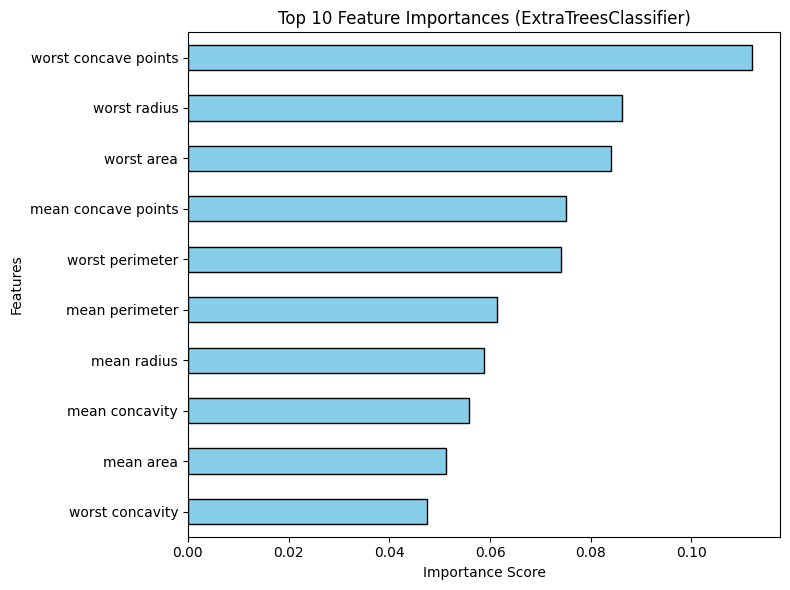

In [ ]:
# TODO: fit ExtraTrees (200 trees, random_state=7), store importances in imp, plot barh of top 10
...
et = ExtraTreesClassifier(n_estimators=200, random_state=7)
et.fit(X, y)


imp = pd.Series(et.feature_importances_, index=X.columns).sort_values()


plt.figure(figsize=(8, 6))
imp.tail(10).plot(kind="barh", color="skyblue", edgecolor="black")
plt.title("Top 10 Feature Importances (ExtraTreesClassifier)")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.tight_layout()
plt.show()


et_top10 = imp.tail(10).index.tolist()

**Exercise C.8 (decision).** Keep a feature if **at least two of the three** methods (SelectKBest top 10, RFE, ExtraTrees top 10) chose it. Store the result in a list called `selected`.

In [ ]:
# TODO: vote across the three methods
...
all_selected = kbest_top10 + rfe_features + et_top10
feature_counts = pd.Series(all_selected).value_counts()

selected = feature_counts[feature_counts >= 2].index.tolist()

print(f"Features selected by at least 2 methods ({len(selected)} total):\n", selected)

Features selected by at least 2 methods (10 total):
 ['worst concave points', 'worst perimeter', 'mean concave points', 'worst radius', 'worst area', 'worst concavity', 'mean perimeter', 'mean radius', 'mean area', 'mean concavity']


> **Caution (data leakage).** Here selection used the whole dataset to keep the exercise simple. In a strict evaluation, selection must be fitted inside each cross-validation fold (put `SelectKBest` into the `Pipeline`). You will discuss this in the final questions.

### C.3 Data Transform
**Exercise C.9.** Create a stratified 80/20 train/test split (`random_state=7`). The test set stays untouched until the very end.

In [ ]:
from sklearn.model_selection import train_test_split

# TODO: train_test_split with stratify=y
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=7
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (455, 30)
X_test shape: (114, 30)


**Exercise C.10.** Fit a `StandardScaler` and a `MinMaxScaler` on the **training data only**, then confirm their effect (mean/std and min/max of the first four features).

In [ ]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# Fit scalers on training data
std_scaler = StandardScaler().fit(X_train)
min_max_scaler = MinMaxScaler().fit(X_train)

# Transform
X_train_std = std_scaler.transform(X_train)
X_train_minmax = min_max_scaler.transform(X_train)

print("--- Standard Scaler Verification (Mean & Std of first 4 features) ---")
print("Means (should be approx 0):", X_train_std[:, :4].mean(axis=0).round(4))
print("Stds (should be approx 1): ", X_train_std[:, :4].std(axis=0).round(4))

print("\n--- MinMax Scaler Verification (Min & Max of first 4 features) ---")
print("Mins (should be 0):", X_train_minmax[:, :4].min(axis=0).round(4))
print("Maxs (should be 1):", X_train_minmax[:, :4].max(axis=0).round(4))

--- Standard Scaler Verification (Mean & Std of first 4 features) ---
Means (should be approx 0): [ 0. -0. -0. -0.]
Stds (should be approx 1):  [1. 1. 1. 1.]

--- MinMax Scaler Verification (Min & Max of first 4 features) ---
Mins (should be 0): [0. 0. 0. 0.]
Maxs (should be 1): [1. 1. 1. 1.]


**Bonus C.11.** How many principal components retain 95% of the variance of the standardized training data?

In [ ]:
from sklearn.decomposition import PCA

pca = PCA().fit(X_train_std)


cum_var = np.cumsum(pca.explained_variance_ratio_)

n_components_95 = np.argmax(cum_var >= 0.95) + 1

print(f"Number of components retaining 95% variance: {n_components_95}")
print(f"Cumulative variance explained: {cum_var[n_components_95 - 1]:.4f}")

Number of components retaining 95% variance: 10
Cumulative variance explained: 0.9560


---
## D. Evaluate Algorithm

We use **stratified 10-fold cross-validation** on the training set as our test harness. Scaling is placed inside a `Pipeline` so it is re-fitted in every fold: this avoids leakage.

**Exercise D.1.** Define the six candidate models: Logistic Regression, LDA, KNN, CART, Gaussian Naive Bayes and SVM.

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline

seed = 7
kfold = StratifiedKFold(n_splits=10, shuffle=True, random_state=seed)

models = {
    "LR": LogisticRegression(max_iter=1000, random_state=seed),
    "LDA": LinearDiscriminantAnalysis(),
    "KNN": KNeighborsClassifier(),
    "CART": DecisionTreeClassifier(random_state=seed),
    "NB": GaussianNB(),
    "SVM": SVC(random_state=seed),
}

def spot_check(models, X_tr, scale):
    """Cross-validated accuracy for every model (optionally scaled inside the pipeline)."""
    results = {}
    for name, model in models.items():
        steps = (
            [("scale", StandardScaler())] if scale else []
        ) + [("model", model)]
        results[name] = cross_val_score(
            Pipeline(steps), X_tr, y_train, cv=kfold, scoring="accuracy"
        )
    return results

**Exercise D.2.** Run the spot-check on all features, once **raw** and once **scaled**, and tabulate the mean accuracies.

In [ ]:
# Call spot_check on raw features and scaled features
raw_results = spot_check(models, X_train, scale=False)
scaled_results = spot_check(models, X_train, scale=True)

# Calculate mean accuracy for each model
raw_means = {name: np.mean(scores) for name, scores in raw_results.items()}
scaled_means = {name: np.mean(scores) for name, scores in scaled_results.items()}

# Create summary DataFrame
summary = pd.DataFrame({
    "raw": pd.Series(raw_means),
    "scaled": pd.Series(scaled_means)
})

display(summary.round(4))

,raw,scaled
LR,0.9450,0.9823
LDA,0.9472,0.9472
KNN,0.9229,0.9649
CART,0.9276,0.9276
NB,0.9341,0.9320
SVM,0.8987,0.9758


✏️ **Question D.3.** Which models benefit from scaling, and why?

> Your answer: Distance-based algorithms ($KNN$ and $SVM$) and linear models with regularized decision boundaries ($LR$ and $LDA$) benefit significantly from feature scaling. Since the raw features span vastly different numerical ranges (such as mean area values in the thousands versus mean smoothness values under 0.2), unscaled distance metrics become heavily biased toward large-magnitude features. Tree-based models like $CART$ remain unaffected because split decisions are invariant to monotonic feature transformations.

**Exercise D.4.** Repeat with the `selected` features only (scaled). Does feature selection help?

In [ ]:
# TODO: spot_check on X_train[selected] and compare against the all-features scaled results
...
results_selected = spot_check(models, X_train[selected], scale=True)


summary["scaled_selected"] = {
    name: scores.mean() for name, scores in results_selected.items()
}

display(summary.round(4))

,raw,scaled,scaled_selected
LR,0.9450,0.9823,0.9604
LDA,0.9472,0.9472,0.9430
KNN,0.9229,0.9649,0.9428
CART,0.9276,0.9276,0.9253
NB,0.9341,0.9320,0.9517
SVM,0.8987,0.9758,0.9539


**Exercise D.5.** Compare the distributions of the scaled models with a box plot.

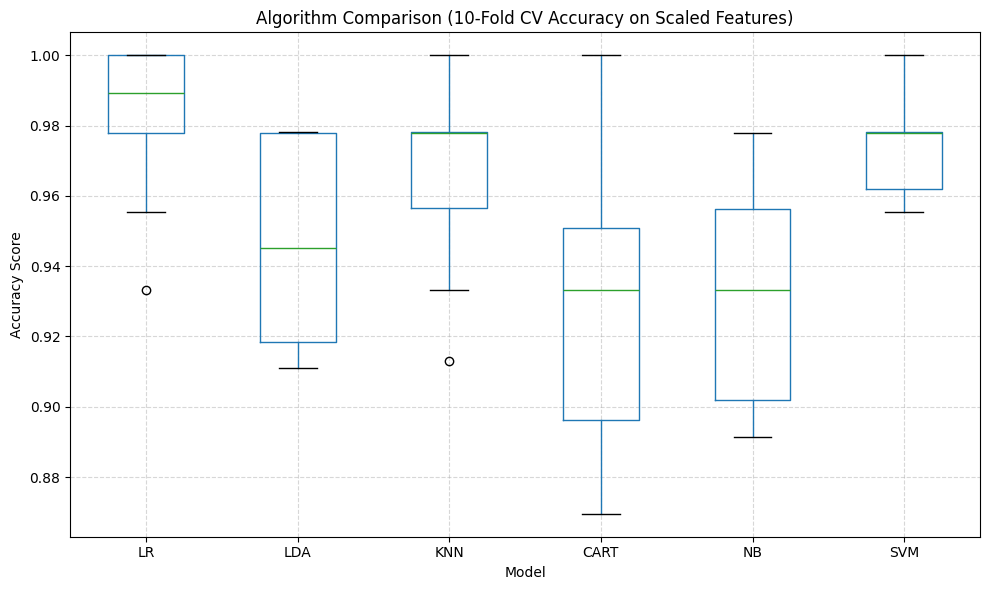

In [ ]:
# TODO: box plot of the 10 fold scores per model
results_scaled_df = pd.DataFrame(scaled_results)

plt.figure(figsize=(10, 6))
results_scaled_df.boxplot()
plt.title("Algorithm Comparison (10-Fold CV Accuracy on Scaled Features)")
plt.xlabel("Model")
plt.ylabel("Accuracy Score")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

**Exercise D.6.** In a medical setting accuracy is not enough. For the best scaled model, cross-validate **accuracy, ROC-AUC and recall for the malignant class** (`pos_label=0`).

In [ ]:
from sklearn.model_selection import cross_validate
from sklearn.metrics import make_scorer, recall_score, accuracy_score, roc_auc_score


recall_malignant = make_scorer(recall_score, pos_label=0)


scoring_metrics = {
    "accuracy": "accuracy",
    "roc_auc": "roc_auc",
    "recall_malignant": recall_malignant
}


best_lr_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000, random_state=seed))
])


cv_results = cross_validate(
    best_lr_pipeline, X_train, y_train, cv=kfold, scoring=scoring_metrics
)


print(f"--- Best Scaled Model (Logistic Regression) Metrics ---")
print(f"Mean Accuracy: {cv_results['test_accuracy'].mean():.4f}")
print(f"Mean ROC-AUC:  {cv_results['test_roc_auc'].mean():.4f}")
print(f"Mean Recall (Malignant, pos_label=0): {cv_results['test_recall_malignant'].mean():.4f}")

--- Best Scaled Model (Logistic Regression) Metrics ---
Mean Accuracy: 0.9823
Mean ROC-AUC:  0.9922
Mean Recall (Malignant, pos_label=0): 0.9647


---
## E. Improve Accuracy

### E.1 Algorithm Tuning
**Exercise E.1.** Tune the SVM (`C`, `gamma`, `kernel`) with `GridSearchCV` inside a scaling pipeline.

In [ ]:
from sklearn.model_selection import GridSearchCV

svm_pipe = Pipeline([("scale", StandardScaler()), ("svm", SVC(random_state=7))])

param_grid_svm = {
    "svm__C": [0.1, 1, 10, 100],
    "svm__gamma": ["scale", 0.001, 0.01, 0.1],
    "svm__kernel": ["rbf", "linear"],
}

grid_svm = GridSearchCV(
    svm_pipe, param_grid_svm, cv=kfold, scoring="accuracy"
)
grid_svm.fit(X_train, y_train)

print("Best SVM Parameters:", grid_svm.best_params_)
print(f"Best SVM Cross-Validated Accuracy: {grid_svm.best_score_:.4f}")

tuned_svm = grid_svm.best_estimator_

Best SVM Parameters: {'svm__C': 0.1, 'svm__gamma': 'scale', 'svm__kernel': 'linear'}
Best SVM Cross-Validated Accuracy: 0.9802


**Exercise E.2.** Tune KNN (`n_neighbors`, `weights`) the same way.

In [ ]:
from sklearn.model_selection import GridSearchCV

knn_pipe = Pipeline([("scale", StandardScaler()), ("knn", KNeighborsClassifier())])

param_grid_knn = {
    "knn__n_neighbors": [3, 5, 7, 9, 11, 15, 21],
    "knn__weights": ["uniform", "distance"],
}

grid_knn = GridSearchCV(
    knn_pipe, param_grid_knn, cv=kfold, scoring="accuracy"
)
grid_knn.fit(X_train, y_train)

print("Best KNN Parameters:", grid_knn.best_params_)
print(f"Best KNN Cross-Validated Accuracy: {grid_knn.best_score_:.4f}")

tuned_knn = grid_knn.best_estimator_

Best KNN Parameters: {'knn__n_neighbors': 3, 'knn__weights': 'uniform'}
Best KNN Cross-Validated Accuracy: 0.9693


### E.2 Ensembles
**Exercise E.3.** Spot-check four ensemble methods (Random Forest, Extra Trees, Gradient Boosting, AdaBoost) and one voting ensemble of the tuned SVM, tuned KNN and Random Forest.

In [ ]:
# TODO: dictionary ensembles, score with spot_check(scale=False), then a hard VotingClassifier
...
ensembles = {
    "RF": RandomForestClassifier(random_state=7),
    "ET": ExtraTreesClassifier(random_state=7),
    "GBM": GradientBoostingClassifier(random_state=7),
    "AB": AdaBoostClassifier(random_state=7),
}


ensemble_results = spot_check(ensembles, X_train, scale=False)


voting_clf = VotingClassifier(
    estimators=[
        ("svm", tuned_svm),
        ("knn", tuned_knn),
        ("rf", RandomForestClassifier(random_state=7)),
    ],
    voting="hard",
)


voting_scores = cross_val_score(
    voting_clf, X_train, y_train, cv=kfold, scoring="accuracy"
)
print(f"Voting Classifier Mean Accuracy: {voting_scores.mean():.4f}")

Voting Classifier Mean Accuracy: 0.9781


**Exercise E.4.** Build a leaderboard (Series sorted by mean CV accuracy) containing both tuned models, the four ensembles and the voting ensemble.

In [ ]:
# TODO: leaderboard Series
...
leaderboard_dict = {
    "Tuned_SVM": grid_svm.best_score_,
    "Tuned_KNN": grid_knn.best_score_,
    "Voting_Ensemble": voting_scores.mean(),
}


for name, scores in ensemble_results.items():
    leaderboard_dict[name] = scores.mean()


leaderboard = pd.Series(leaderboard_dict).sort_values(ascending=False)

print("--- Final Model Leaderboard (Mean CV Accuracy) ---")
display(leaderboard.round(4))

--- Final Model Leaderboard (Mean CV Accuracy) ---


,0
Tuned_SVM,0.9802
Voting_Ensemble,0.9781
ET,0.9736
Tuned_KNN,0.9693
RF,0.9691
GBM,0.9670
AB,0.9626


### E.3 Finalize the Model
**Exercise E.5.** Fit the winner on the full training set and, for the first and only time, evaluate it on the held-out **test set**. Report accuracy, the classification report and a confusion matrix.

--- Final Evaluation for Winner (Tuned_SVM) ---
Test Accuracy: 0.9649

Classification Report:
              precision    recall  f1-score   support

   Malignant       0.95      0.95      0.95        42
      Benign       0.97      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.96      0.96       114
weighted avg       0.96      0.96      0.96       114



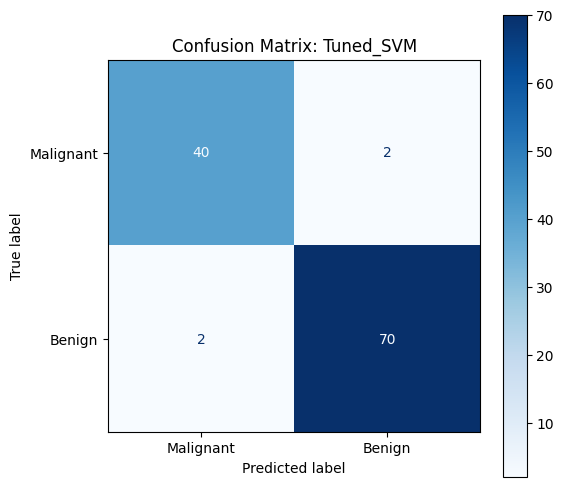

In [ ]:
import joblib
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

model_dict = {
    "Tuned_SVM": tuned_svm,
    "Tuned_KNN": tuned_knn,
    "Voting_Ensemble": voting_clf,
    "RF": RandomForestClassifier(random_state=7),
    "ET": ExtraTreesClassifier(random_state=7),
    "GBM": GradientBoostingClassifier(random_state=7),
    "AB": AdaBoostClassifier(random_state=7),
}

winning_name = leaderboard.index[0]
final_model = model_dict[winning_name]

final_model.fit(X_train, y_train)

y_pred = final_model.predict(X_test)

print(f"--- Final Evaluation for Winner ({winning_name}) ---")
print(f"Test Accuracy: {accuracy_score(y_test, y_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=["Malignant", "Benign"]))

fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["Malignant", "Benign"], cmap="Blues", ax=ax
)
plt.title(f"Confusion Matrix: {winning_name}")
plt.show()

**Exercise E.6.** Save the model with `joblib`, reload it and confirm it reproduces predictions.

In [ ]:
# TODO: joblib.dump, joblib.load, compare first 5 predictions with y_test
...
joblib.dump(final_model, "final_model.joblib")


reloaded_model = joblib.load("final_model.joblib")


original_preds = final_model.predict(X_test[:5])
reloaded_preds = reloaded_model.predict(X_test[:5])

print("First 5 Original Predictions: ", original_preds)
print("First 5 Reloaded Predictions: ", reloaded_preds)
print("Predictions Match:", np.array_equal(original_preds, reloaded_preds))

First 5 Original Predictions:  [0 0 1 0 1]
First 5 Reloaded Predictions:  [0 0 1 0 1]
Predictions Match: True


---
## Reflection Questions
✏️ Answer in a short paragraph each.

1. **Leakage.** Feature selection in Part C used the whole dataset. Explain why this can inflate CV scores and how you would fix it using a `Pipeline`.
2. **Metric choice.** Which metric would you report to a clinician, and why is accuracy alone insufficient?
3. **Model choice.** If two models differ by 0.3% in CV accuracy, how would you decide between them? (Think variance across folds, interpretability, training cost.)
4. **Generalization.** How would your conclusions change with a much smaller or much more imbalanced dataset?
5. **Extension.** Repeat the workbook with a dataset of your choice (e.g., loaded from an ARFF file) and note which steps change.

**Submission checklist:** all `TODO`s completed · all cells run top to bottom · written answers filled in · final test accuracy reported once.

1. Leakage:
Applying feature selection across the entire dataset before splitting allows information from the validation and test sets to leak into the feature selection phase, artificially inflating cross-validation scores. To fix this, feature selection steps (like SelectKBest or RFE) must be embedded inside an sklearn.pipeline.Pipeline, ensuring selection is re-fitted strictly on training folds within each cross-validation step.2. Metric choice:
I would report recall for the malignant class (pos_label=0) along with $F_1$-score and ROC-AUC. Accuracy alone is insufficient in medical diagnostics because a model could achieve high accuracy by predicting the majority class while missing critical malignant tumors (false negatives), which carries severe health risks.3. Model choice:
When two models differ by only 0.3% in CV accuracy, I would select the winner based on variance across CV folds (favoring lower standard deviation), interpretability (simpler linear or tree models over black-box ensembles), and training/inference cost. A simpler model with lower fold variance is far more reliable and easier to audit in production.4. Generalization:
With a much smaller or highly imbalanced dataset, cross-validation variance would increase significantly, making models prone to overfitting. We would need stronger regularization, stratified sampling methods, and specialized imbalance techniques (such as SMOTE oversampling or class-weighted loss functions) to ensure reliable generalization.5. Extension:
When repeating this workflow on a new dataset (e.g., loaded from an ARFF file using scipy.io.arff), the primary changes occur during data loading and initial preprocessing (handling categorical variables, missing value imputation, and encoding target labels). The core evaluation harness, pipeline scaling, hyperparameter tuning, and model persistence steps remain identical.